> **Worked example of the method.** This notebook is saved with its outputs, so it can be read without running anything. The Münster data are not part of this repository; to re-run it, place the final model inputs in `data/muenster/model_inputs/` and the saved solutions and audited table in `results/muenster/` (the folders named in `config/muenster.toml`, `[outputs]`). The data sources are listed in `docs/MUENSTER_DATA_SOURCES.md`.

**MSc thesis** - *Beyond Efficiency: A Rawlsian Approach to Facility Location for Equitable Access to Urban Opportunities*
(Samuel Yohanna)

**Four distinctions to keep in mind when reading the results.**

1. **Utilitarian = aggregate efficiency.** It minimises the total walking time of all estimated children in the city
   (child-minutes); it gives no priority to any group.
2. **Individual Rawlsian = the worst-served Q4 location.** It minimises the longest walk of any single demand location
   in Q4, unweighted by its number of children, then (Stage 2) the dispersion of Q4 walking times.
3. **District Rawlsian = the worst-served Q4 district mean.** It minimises the largest child-weighted mean walking time
   of a Q4 district.
4. **Estimated potential demand, not observed demand.** Demand is the modelled number of children aged 0-5 at
   residential locations (Section 2); observed addresses, Kita enrolment and waiting lists are not used.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from childcare_access import evaluation, report, solutions
from childcare_access.saved_inputs import AUDIT_FINAL, INPUTS_FINAL, RUN_FINAL, load_primary_inputs

pd.set_option("display.float_format", lambda v: f"{v:,.3f}" if v == 0 or abs(v) >= 1e-3 else f"{v:.1e}")
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110})

data = load_primary_inputs(INPUTS_FINAL)  # the final model inputs (read only)
districts, kitas, cands = data["districts"], data["existing_kitas"], data["candidate_sites"]
demand = data["demand"].set_index("demand_id")

## 1. Study area and data

| Data | Type | Reference | Role |
|---|---|---|---|
| 45 statistical districts (City of Münster) | geometry | - | spatial units |
| Children aged 0-2 and 3-5 per district | **projected** | 2026 | district totals of demand |
| Census 2022 grid (100 m), children < 3 and 3-5 | **observed** | 15 May 2022 | where children live *within* a district |
| ALKIS residential buildings (Geobasis NRW) | observed | 2023-2026 | residential locations and footprints |
| Four social indicators per district | observed | 31 Dec 2025 | vulnerability index |
| OpenStreetMap highways, historical snapshot | observed | 2026-06-20 | pedestrian network |
| OpenStreetMap Kitas (`amenity=kindergarten`) | observed | 2026-06-20 | existing facilities |

Sources and preparation: `docs/METHODS.md`.

In [2]:
checks = pd.DataFrame(data["validation_report"]["checks"])
buildings = data["residential_buildings"]
display(
    pd.Series(
        {
            "Statistical districts": len(districts),
            "Residential buildings (ALKIS)": len(buildings),
            "  of which excluded (student-only residences)": int(buildings["exclude_student_dormitory"].sum()),
            "Existing Kitas": len(kitas),
            "Demand locations (network node x district)": len(demand),
            "Candidate sites": len(cands),
            "Walking-network nodes": data["graph_base"].number_of_nodes(),
        },
        name="count",
    ).to_frame()
)
print(f"Input build checks passed: {checks['passed'].sum()} of {len(checks)}")

,count
Statistical districts,45
Residential buildings (ALKIS),57006
of which excluded (student-only residences),41
Existing Kitas,227
Demand locations (network node x district),11275
Candidate sites,18278
Walking-network nodes,62284


Input build checks passed: 11 of 11


## 2. Estimated childcare demand

Demand is the **estimated** number of children aged 0-5 in 2026 at each place of residence (census-grid allocation):

1. the projected district total $C_d$ is split over the Census 2022 grid cells of the district in proportion to
   their observed children ($S_g$);
2. each cell's share is split over its residential buildings by footprint area;
3. a cell with children but no eligible building keeps its children at the cell centre (fallback origin);
4. buildings are attached to the nearest network node; children at the same node and district form one
   **demand location** $i$ with demand $D_i$.

$$D_b = C_d\, S_g\, \frac{A_b}{\sum_{k \in B_g} A_k}, \qquad \sum_{i \in d} D_i = C_d .$$

This is **estimated potential demand**: modelled residential locations of children who could need a place, not
observed demand (observed addresses of children, Kita enrolment or waiting lists, none of which are used). The allocation and its
result are described in `docs/METHODS.md` (Section 2).

,value
Projected children 0-5 (sum of districts),"14,960.000"
Estimated demand (sum over locations),"14,960.000"
Largest district total error,2.8e-14
Demand locations,"11,275.000"
in Q4 districts,"3,490.000"
Estimated children in Q4 districts,"5,323.000"


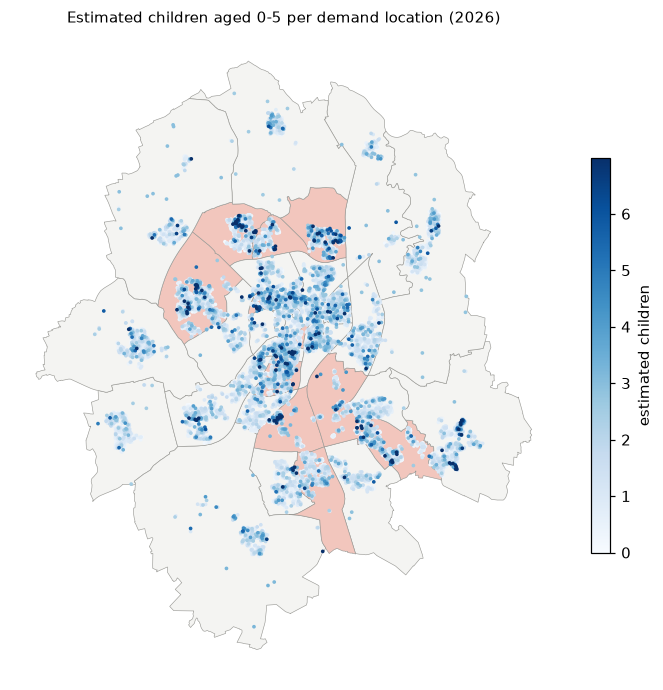

In [3]:
totals = data["children"].set_index("district_id")["children_0_5"]
q4 = demand["least_advantaged"]
error = (demand.groupby("district_id")["estimated_demand"].sum() - totals).abs().max()
display(
    pd.Series(
        {
            "Projected children 0-5 (sum of districts)": totals.sum(),
            "Estimated demand (sum over locations)": demand["estimated_demand"].sum(),
            "Largest district total error": error,
            "Demand locations": len(demand),
            "  in Q4 districts": int(q4.sum()),
            "Estimated children in Q4 districts": demand.loc[q4, "estimated_demand"].sum(),
        },
        name="value",
    ).to_frame()
)
fig = report.demand_map(districts, data["demand"])

## 3. Vulnerability and the priority group

The childcare-vulnerability index of district $d$ is the equal-weight mean of four min-max-normalised indicators
(2025): SGB II recipients aged 15-64 and aged 0-14, children with a migration history, and children in
single-parent households.

$$v_d = \frac14 \sum_{k=1}^{4} \frac{x_{dk} - \min_{d'} x_{d'k}}{\max_{d'} x_{d'k} - \min_{d'} x_{d'k}}$$

**Q4** is the set of districts with $v_d$ at or above the 75th percentile of the 45 district values. It is a
**district** classification: every demand location in a Q4 district counts as Q4. No child has an individually
measured vulnerability.

In [4]:
groups = data["district_vulnerability"].set_index("district_name")
children_q4 = demand[q4].groupby("district_name")["estimated_demand"].sum()
table = groups.loc[groups["least_advantaged"], ["childcare_vulnerability_index"]].assign(children=children_q4)
table = table.sort_values("childcare_vulnerability_index", ascending=False).rename(
    columns={"childcare_vulnerability_index": "index"}
)
display(table)
print(
    f"Q4: {len(table)} of {len(groups)} districts; threshold {groups['least_advantaged_threshold'].iloc[0]:.4f}; "
    f"{table['children'].sum():.0f} estimated children "
    f"({table['children'].sum() / demand['estimated_demand'].sum():.1%})"
)

,index,children
district_name,,
Coerde,0.943,659.000
Berg Fidel,0.827,379.000
Kinderhaus-West,0.689,586.000
Bahnhof,0.674,37.000
Neutor,0.642,172.000
Angelmodde,0.550,528.000
Kinderhaus-Ost,0.538,286.000
Gremmendorf-West,0.500,465.000
Schützenhof,0.454,358.000


Q4: 12 of 45 districts; threshold 0.3853; 5323 estimated children (35.6%)


## 4. Walking network and current access

Walking times come from a pedestrian network built from the OSM snapshot of 2026-06-20 at 83.33 m/min = 5 km/h on
every edge. Access rules follow the OSM tags: ways closed to pedestrians (including motorroads) are excluded, private
ways are used only at the start or end of a trip, and roads whose pedestrians must use a separately mapped sidewalk
are kept as a proxy for that sidewalk (`docs/METHODS.md`, Section 3). In the code and the build reports this final
rule set is named `pedestrian_access_v3` (`src/childcare_access/pedestrian_network.py`). A demand location's **access** $t_i$ is its walking
time to the **nearest open** Kita. Access is capacity-free: facility sizes and waiting lists are not modelled.

Below, *mean* is unweighted over demand locations and *demand-weighted mean* weights each location by its
estimated children; both are reported because they answer different questions.

,Current
City mean,5.573
City demand-weighted mean,5.527
City P90,9.758
Q4 demand-weighted mean,5.417
Worst Q4 location,24.532
Worst Q4 district mean,8.478
Worst Q4 district,Gremmendorf-West


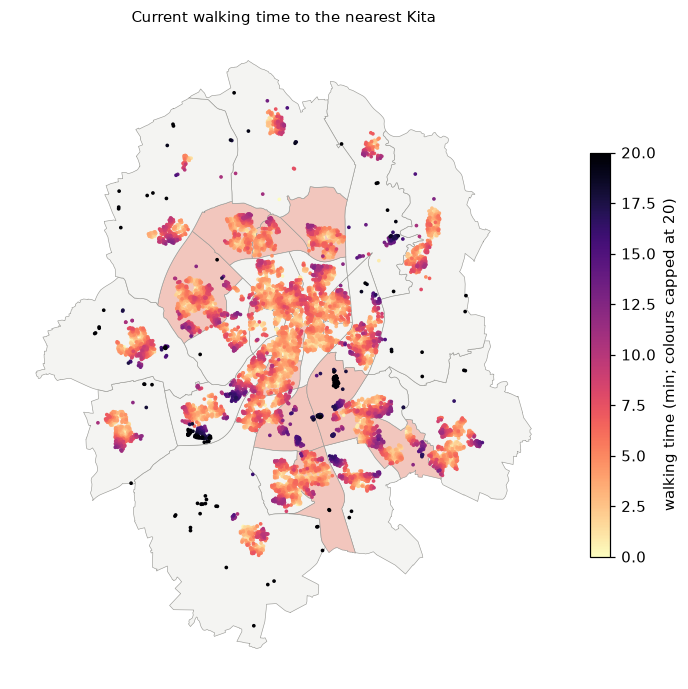

In [5]:
nodes = cands.set_index("facility_id")["nearest_node"]
times = {"current": evaluation.scenario_times(data["graph"], demand, kitas["nearest_node"], nodes)}
display(
    report.indicators({"Current": times["current"]}, demand).loc[
        [
            "City mean",
            "City demand-weighted mean",
            "City P90",
            "Q4 demand-weighted mean",
            "Worst Q4 location",
            "Worst Q4 district mean",
            "Worst Q4 district",
        ]
    ]
)
fig = report.access_map(districts, data["demand"], times["current"], "Current walking time to the nearest Kita")

## 5. Candidate locations

Each network node of an eligible residential building is a candidate site (18,278 sites). Residential buildings
are a **proxy** for places where a Kita could be located; land availability, zoning and building suitability are
not assessed. For the District Rawlsian model, a dominance screen removes every candidate for which another
candidate is at least as good for every Q4 location. Replacing a removed candidate by its retained dominator never
lengthens a Q4 walk, so the best District objective on the 4,599 retained sites equals that on all candidates.

In [6]:
print(
    f"Candidates: {len(cands):,}; retained by the dominance screen for the District model: "
    f"{len(data['screen_retained_indices']):,}"
)

Candidates: 18,278; retained by the dominance screen for the District model: 4,599


## 6. The three optimisation models

All three choose $P$ sites $S$ from the candidates; each demand location uses its nearest open Kita (existing or
new), and $t_i(S)$ is that walking time.

| Model | Objective | Who is prioritised |
|---|---|---|
| Utilitarian | $\min \sum_{i} D_i\, t_i$ | every child equally (total child-minutes) |
| Individual Rawlsian | Stage 1: $Z^* = \min \max_{i \in Q_4} t_i$; Stage 2: $\min \sum_{i \in Q_4} (t_i - \bar t)^2$ s.t. $\max_{i \in Q_4} t_i \le Z^* + \varepsilon$ | the worst-served Q4 **location** (unweighted) |
| District Rawlsian | $\min \max_{d \in Q_4} A_d$, $A_d = \sum_{i \in d} D_i t_i / \sum_{i \in d} D_i$ | the Q4 **district** whose average child walks longest |

$\varepsilon = 10^{-6}$ min only absorbs rounding. The objectives differ in kind: total child-minutes (Utilitarian),
a single location's minutes (Individual), and a district's average minutes (District).

The two Rawlsian readings are not interchangeable. The Individual model is **unweighted** (a location-based, not a
demand-weighted, maximin): a Q4 location counts the same whatever its number of children, and only the longest walk (then the dispersion) matters, so it can help very few
children. The District model weights by children *within* each district and protects the district whose average
child walks longest; a long walk at a sparsely populated location barely moves its district mean.

## 7. Results: efficiency and equity

All three models are solved on **identical inputs** (a direct comparison), so the differences
below are due to the objectives alone.

In [7]:
best = solutions.load_reported_solutions(RUN_FINAL)
exact = solutions.load_alternative_solutions(RUN_FINAL)["individual_exact_stage2"]
for key, s in {**best, "individual_exact_stage2": exact}.items():
    times[key] = evaluation.scenario_times(data["graph"], demand, kitas["nearest_node"], nodes, s.sites)

ind, gain = report.indicators(times, demand), report.gains(times, demand)
audit = pd.read_csv(AUDIT_FINAL / "table_primary.csv", index_col=0)
worst = max(
    report.check_against_audit(ind, audit, report.INDICATOR_ROWS),
    report.check_against_audit(gain, audit, report.GAIN_ROWS),
)
# the recomputed walking times reproduce each model's saved objective
assert abs((times["utilitarian"] * demand["estimated_demand"]).sum() - best["utilitarian"].objective_value) < 1e-6
assert abs(times["individual"][q4].max() - best["individual"].objective_value) < 1e-9
assert abs(ind.at["Worst Q4 district mean", "district"] - best["district"].objective_value) < 1e-9
print(f"Recomputed indicators match the audited table (largest difference {worst:.1e}) and the saved objectives.")

names = {
    "current": "Current",
    **{k: v[0] for k, v in report.MODELS.items()},
    "individual_exact_stage2": "Individual: exact Stage 2 (reference)",
}
display(ind.loc[[*report.INDICATOR_ROWS, "Worst Q4 district"]].rename(columns=names))
display(gain.loc[list(report.GAIN_ROWS)].rename(columns=names))

Recomputed indicators match the audited table (largest difference 8.9e-16) and the saved objectives.


,Current,Utilitarian,Individual Rawlsian,District Rawlsian,Individual: exact Stage 2 (reference)
City mean,5.573,5.379,5.490,5.455,5.479
City demand-weighted mean,5.527,5.285,5.422,5.354,5.421
City median,4.785,4.690,4.774,4.710,4.759
City SD,3.858,3.567,3.664,3.712,3.666
City P90,9.758,9.406,9.627,9.522,9.610
City maximum,50.481,50.481,50.481,50.481,50.481
Q4 mean,5.783,5.480,5.530,5.401,5.490
Q4 demand-weighted mean,5.417,5.020,5.191,4.930,5.163
Q4 median,5.000,4.798,4.953,4.734,4.915
Q4 SD,3.822,3.366,3.219,3.330,3.210


,Utilitarian,Individual Rawlsian,District Rawlsian,Individual: exact Stage 2 (reference)
City child-min saved,"3,624.541","1,575.287","2,588.960","1,590.971"
Q4 child-min saved,"2,112.477","1,199.919","2,588.960","1,350.323"
"Children improved (> 0), city",500.066,180.911,576.724,223.554
"Children improved (> 0), Q4",382.196,154.095,576.724,196.737
"Children improved (>= 5 min), city",350.686,138.383,232.816,148.534
"Children improved (>= 5 min), Q4",232.816,112.558,232.816,122.709


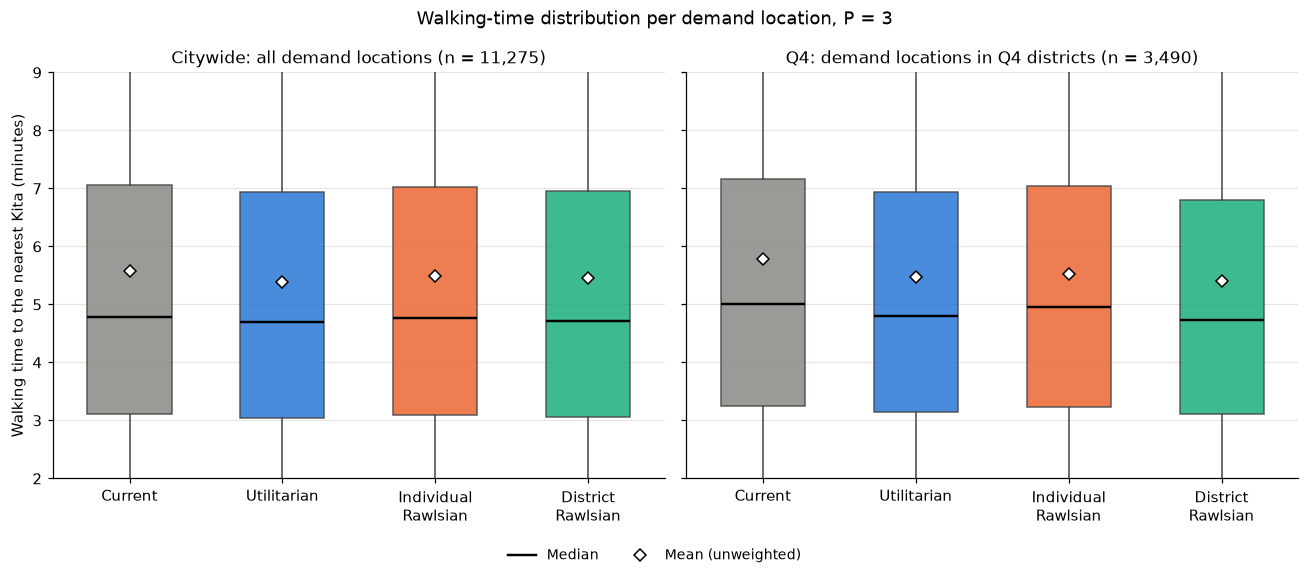

In [8]:
# Per-location walking times from the final inputs and the saved P = 3 solutions.
# Each demand location counts once; estimated children are not used as weights.
# Outlier markers are hidden and the axis is zoomed to 2-9 min for display only (whiskers beyond it are clipped);
# all locations enter every statistic.
from matplotlib.lines import Line2D

scenarios = {"current": ("Current", "#8a8985"), **report.MODELS}
panels = {
    "Citywide: all demand locations": pd.Series(True, index=demand.index),
    "Q4: demand locations in Q4 districts": q4,
}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, (title, selected) in zip(axes, panels.items(), strict=True):
    values = [times[key][selected] for key in scenarios]
    box = ax.boxplot(
        values,
        patch_artist=True,
        widths=0.55,
        whis=1.5,
        showfliers=False,
        showmeans=True,
        medianprops={"color": "black", "linewidth": 1.6},
        meanprops={"marker": "D", "markersize": 6, "markerfacecolor": "white", "markeredgecolor": "black"},
        whiskerprops={"color": "#444444"},
        capprops={"color": "#444444"},
    )
    for patch, (_, colour) in zip(box["boxes"], scenarios.values(), strict=True):
        patch.set_facecolor(colour)
        patch.set_alpha(0.85)
        patch.set_edgecolor("#444444")
    ax.set_xticks(range(1, len(scenarios) + 1), [label.replace(" ", "\n") for label, _ in scenarios.values()])
    ax.set_title(f"{title} (n = {int(selected.sum()):,})", fontsize=11)
    ax.set_ylim(2, 9)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Walking time to the nearest Kita (minutes)")
fig.legend(
    handles=[
        Line2D([], [], color="black", linewidth=1.6, label="Median"),
        Line2D([], [], marker="D", linestyle="none", markersize=6, markerfacecolor="white", markeredgecolor="black", label="Mean (unweighted)"),
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=9,
)
fig.suptitle("Walking-time distribution per demand location, P = 3", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()


*Box plots show the distribution of walking times across demand locations. The y-axis is zoomed to 2–9 minutes in
both panels to highlight differences in the central distributions; whiskers extending beyond this range are clipped.
Outlier markers are omitted. All observations remain included in the calculations.*

Each demand location counts once (estimated children are not weights). The line in a box is the median, the diamond
the unweighted mean, the box the middle 50% of locations, and the whiskers reach up to 1.5 box heights beyond the box.
Both panels use the same axis.

- **The bulk barely moves.** Three new sites change the walk of few locations (307, 133 and 341 of 11,275 for the
  Utilitarian, Individual and District models), so the median and box shift by at most about 0.4 min in either panel.
- **Citywide, the longest walks are outside Q4.** They lie beyond the displayed range (up to 50.5 min) and are the same
  in all four scenarios; none of the models reaches those locations.
- **Q4 upper tail.** The longest Q4 walk (beyond the displayed range; see the table above) falls from 24.5 min to 21.8 min
  (Utilitarian, District) and to 18.9 min (Individual Rawlsian), as its Stage 1 objective requires.
- **Q4 centre.** The District Rawlsian model shifts the Q4 distribution down the most (median 5.00 to 4.73 min, upper
  quartile 7.17 to 6.79 min, unweighted mean 5.78 to 5.40 min); all 341 locations it improves are in Q4.

**Relative change against the current situation.** Each percentage is (model value / current value) - 1 for the same
indicator, P = 3, final inputs; a negative value is a shorter walk or a smaller spread. The worst Q4 district mean compares two maxima, which may belong to different districts
(the results table above names them). Percentages of different metrics measure different things and are not comparable with
each other.

In [9]:
display(report.relative_change(ind).rename(columns=names).style.format("{:+.1%}"))

,Utilitarian,Individual Rawlsian,District Rawlsian,Individual: exact Stage 2 (reference)
City mean,-3.5%,-1.5%,-2.1%,-1.7%
City demand-weighted mean,-4.4%,-1.9%,-3.1%,-1.9%
City median,-2.0%,-0.2%,-1.6%,-0.5%
City SD,-7.6%,-5.0%,-3.8%,-5.0%
City P90,-3.6%,-1.3%,-2.4%,-1.5%
City maximum,+0.0%,+0.0%,+0.0%,+0.0%
Q4 mean,-5.3%,-4.4%,-6.6%,-5.1%
Q4 demand-weighted mean,-7.3%,-4.2%,-9.0%,-4.7%
Q4 median,-4.0%,-0.9%,-5.3%,-1.7%
Q4 SD,-11.9%,-15.8%,-12.9%,-16.0%


**Walks of the vulnerable group.** The three panels compare the scenarios on the Q4 mean and on the two maximum
measures: the longest walk of any Q4 location, which the Individual Rawlsian model minimises first, and the highest Q4
district mean, which the District Rawlsian model minimises. The worst Q4 district may differ between scenarios.

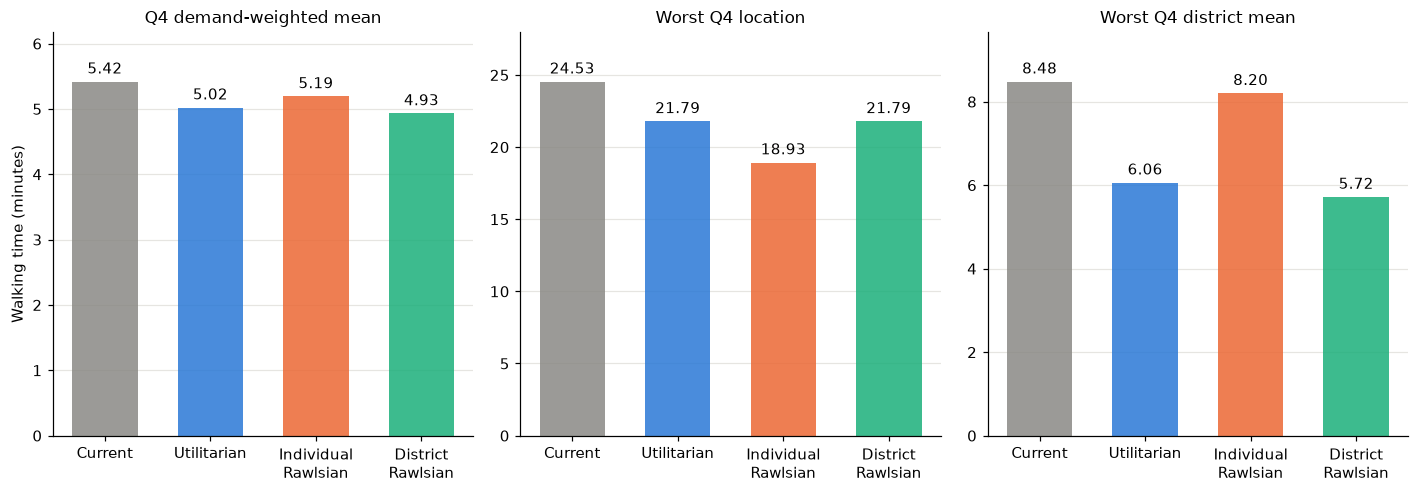

In [10]:
fig = report.priority_chart(ind)

In [11]:
u, i, d = gain["utilitarian"], gain["individual"], gain["district"]
ratio = (u["City child-min saved"] - d["City child-min saved"]) / (d["Q4 child-min saved"] - u["Q4 child-min saved"])
display(
    Markdown(f"""
- **Efficiency.** The Utilitarian sites save the most child-minutes ({u["City child-min saved"]:,.0f}); the city
  demand-weighted mean falls from {ind.at["City demand-weighted mean", "current"]:.3f} to
  {ind.at["City demand-weighted mean", "utilitarian"]:.3f} min. {u["Q4 child-min saved"] / u["City child-min saved"]:.0%}
  of its savings fall in Q4.
- **Worst Q4 location.** The Individual Rawlsian model lowers the longest Q4 walk from
  {ind.at["Worst Q4 location", "current"]:.2f} to {ind.at["Worst Q4 location", "individual"]:.2f} min,
  against {ind.at["Worst Q4 location", "utilitarian"]:.2f} min for the Utilitarian sites. It helps few children
  ({i["Children improved (> 0), city"]:.0f} improved): its objective concerns only the worst-served Q4 location.
- **Worst Q4 district.** The District Rawlsian model lowers the worst Q4 district mean from
  {ind.at["Worst Q4 district mean", "current"]:.3f} ({ind.at["Worst Q4 district", "current"]}) to
  {ind.at["Worst Q4 district mean", "district"]:.3f} min, against {ind.at["Worst Q4 district mean", "utilitarian"]:.3f}
  for the Utilitarian sites. All its savings ({d["Q4 child-min saved"]:,.0f} child-minutes) fall in Q4, the most of
  the three models.
- **Trade-off.** Moving from the Utilitarian to the District sites costs {ratio:.2f} city child-minutes per extra Q4
  child-minute saved.
- **Exact Stage 2 reference.** Its Q4 SD ({ind.at["Q4 SD", "individual_exact_stage2"]:.4f}) is only slightly below the
  reported {ind.at["Q4 SD", "individual"]:.4f}; it is a reference, not the reported result.
""")
)


- **Efficiency.** The Utilitarian sites save the most child-minutes (3,625); the city
  demand-weighted mean falls from 5.527 to
  5.285 min. 58%
  of its savings fall in Q4.
- **Worst Q4 location.** The Individual Rawlsian model lowers the longest Q4 walk from
  24.53 to 18.93 min,
  against 21.79 min for the Utilitarian sites. It helps few children
  (181 improved): its objective concerns only the worst-served Q4 location.
- **Worst Q4 district.** The District Rawlsian model lowers the worst Q4 district mean from
  8.478 (Gremmendorf-West) to
  5.716 min, against 6.058
  for the Utilitarian sites. All its savings (2,589 child-minutes) fall in Q4, the most of
  the three models.
- **Trade-off.** Moving from the Utilitarian to the District sites costs 2.17 city child-minutes per extra Q4
  child-minute saved.
- **Exact Stage 2 reference.** Its Q4 SD (3.2101) is only slightly below the
  reported 3.2187; it is a reference, not the reported result.


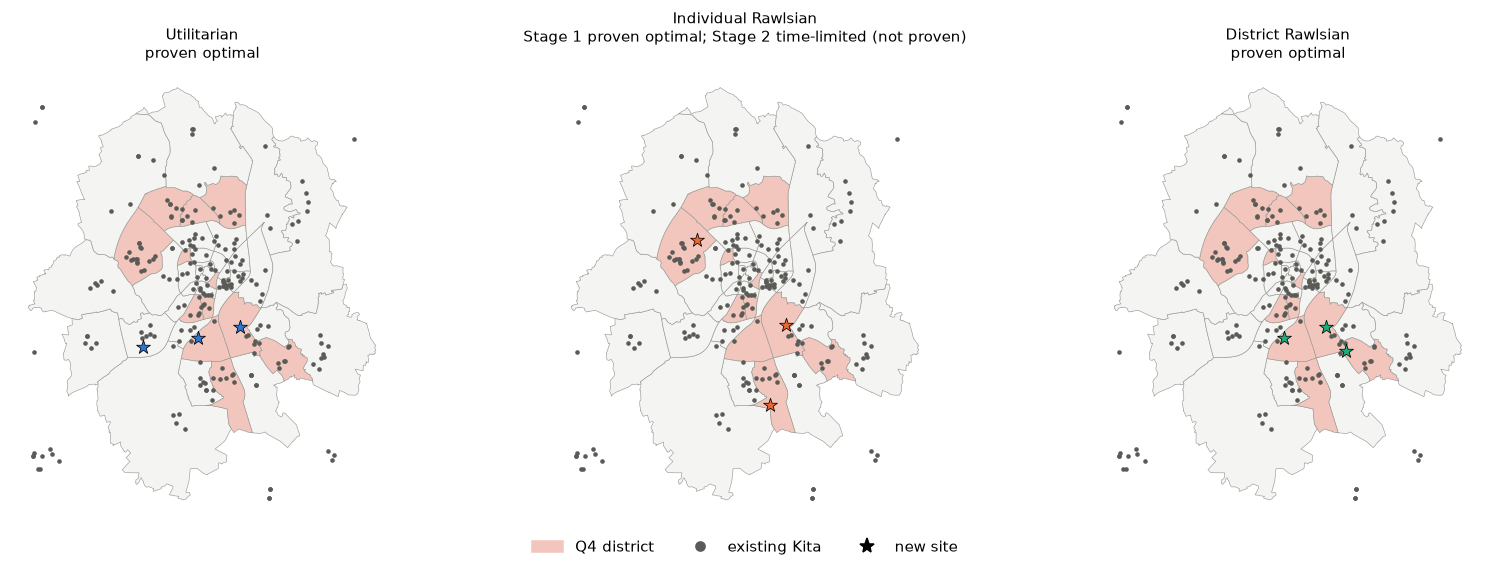

In [12]:
fig = report.sites_map(districts, kitas, cands, best)

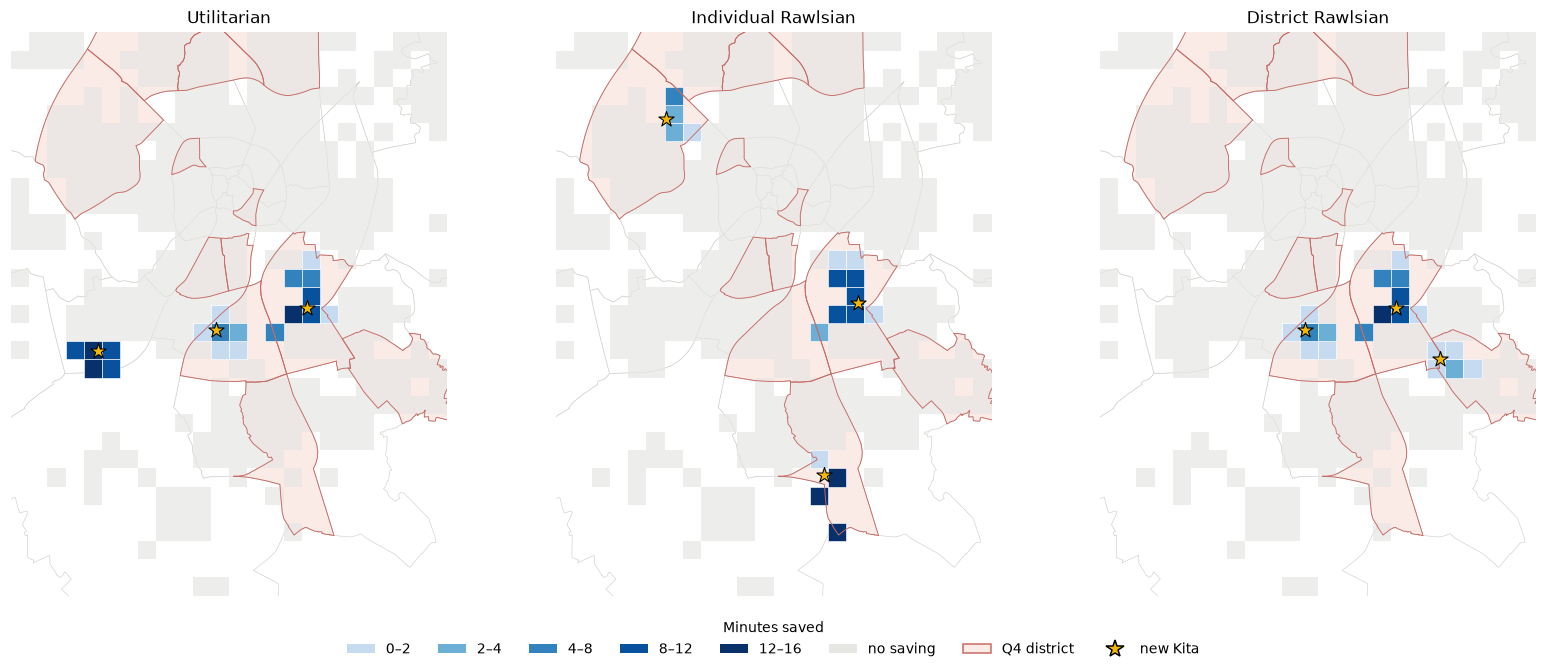

In [13]:
# Walking-time savings of each model per 500 m grid cell (EPSG:25832), final P = 3 solutions.
# Cell value = demand-weighted mean reduction over all demand locations in the cell,
#     sum_i D_i (c_i - t_i) / sum_i D_i,  where locations without a saving count as 0.
# Cells without demand locations are not drawn; populated cells without any saving are light grey.
# All panels share the grid, the classes and the map extent (every location with a saving lies inside it).
import geopandas as gpd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from shapely.geometry import box as cell_box

CELL = 500  # metres
classes = [0, 2, 4, 8, 12, 16]  # minutes saved
cmap = ListedColormap(["#c6dbef", "#6baed6", "#3182bd", "#08519c", "#08306b"])
norm = BoundaryNorm(classes, cmap.N)

points = data["demand"].to_crs(25832).set_index("demand_id").loc[demand.index]
cx, cy = (points.geometry.x // CELL).astype(int), (points.geometry.y // CELL).astype(int)
shape = districts.to_crs(25832)
sites = cands.set_index("facility_id").to_crs(25832)


def saving_cells(key):
    saving = (times["current"] - times[key]).clip(lower=0)
    frame = pd.DataFrame({"cx": cx, "cy": cy, "D": demand["estimated_demand"], "DS": demand["estimated_demand"] * saving})
    cells = frame.groupby(["cx", "cy"])[["D", "DS"]].sum().reset_index()
    cells = cells[cells["D"] > 0].assign(saving=lambda c: c["DS"] / c["D"])
    geometry = [cell_box(x * CELL, y * CELL, (x + 1) * CELL, (y + 1) * CELL) for x, y in zip(cells["cx"], cells["cy"])]
    return gpd.GeoDataFrame(cells, geometry=geometry, crs=25832)


grids = {key: saving_cells(key) for key in report.MODELS}
# the same cells and the same demand weights in every scenario; the cells reproduce each model's child-minutes saved
reference = grids["utilitarian"].set_index(["cx", "cy"])["D"]
assert all(g.set_index(["cx", "cy"])["D"].equals(reference) for g in grids.values())
gained = pd.concat([g[g["saving"] > 1e-9] for g in grids.values()])
assert all(abs((g["DS"]).sum() - gain.at["City child-min saved", k]) < 1e-6 for k, g in grids.items())
x0, y0, x1, y1 = gained.total_bounds
pad = 1500
fig, axes = plt.subplots(1, 3, figsize=(15, 6.0))
for ax, (key, (name, _)) in zip(axes, report.MODELS.items(), strict=True):
    cells = grids[key]
    has_gain = cells["saving"] > 1e-9
    shape.plot(ax=ax, color=shape["least_advantaged"].map({True: "#fbebe7", False: "white"}), edgecolor="#cfcfcb", linewidth=0.4)
    cells[~has_gain].plot(ax=ax, color="#e6e6e3", alpha=0.7, linewidth=0)
    shape[shape["least_advantaged"]].boundary.plot(ax=ax, color="#c96b66", linewidth=0.6)
    cells[has_gain].plot(ax=ax, column="saving", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.4)
    sites.loc[list(best[key].sites)].plot(ax=ax, marker="*", markersize=110, color="#f5b800", edgecolor="black", linewidth=0.7, zorder=5)
    ax.set_xlim(x0 - pad, x1 + pad)
    ax.set_ylim(y0 - pad, y1 + pad)
    ax.set_title(name, fontsize=11)
    ax.set_axis_off()
handles = [Patch(facecolor=cmap(i), label=f"{lo:g}–{hi:g}") for i, (lo, hi) in enumerate(zip(classes, classes[1:]))]
handles += [
    Patch(facecolor="#e6e6e3", label="no saving"),
    Patch(facecolor="#fbebe7", edgecolor="#c96b66", label="Q4 district"),
    plt.Line2D([], [], marker="*", color="#f5b800", markeredgecolor="black", markersize=12, ls="", label="new Kita"),
]
fig.legend(handles=handles, loc="lower center", ncol=8, frameon=False, fontsize=9,
           title="Minutes saved", title_fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


*Spatial distribution of walking-time savings following the addition of three Kitas. Each 500 m grid cell represents
the demand-weighted mean reduction in walking time for its demand locations. Darker blue indicates greater savings.
Grey cells contain estimated demand but show no improvement.*

**Method.** A cell's value is $\sum_i D_i (c_i - t_i) / \sum_i D_i$ over all demand locations in the cell; locations
without a saving count as 0. All three panels use the same grid, the same demand weights, the same classes and the
same map extent, which contains every location with a saving. Cells without demand locations are not drawn, so they
are never shown as zero improvement. The cells together reproduce each model's child-minutes saved, and the highest
cell values (15.8, 15.0 and 14.2 min) are close to the largest single-location savings (16.1, 15.0 and 14.2 min), so
the grid does not hide local peaks.

- **Utilitarian.** Savings cluster around its three sites; the largest lie around the site outside Q4 (Mecklenbeck).
- **Individual Rawlsian.** Most improved locations lie around its Gremmendorf-West site. The site in the north-west
  Q4 district (Gievenbeck) gives mostly small savings to few locations; the largest single savings lie around the
  southern site (Hiltrup-Mitte), partly outside Q4.
- **District Rawlsian.** Every location with a saving lies in a Q4 district.

## 8. Limitations

- Demand is estimated from projected district totals and 2022 census shares, not observed residences.
- Q4 is a district classification; within-district differences in vulnerability are not represented.
- Access is the walking time to the nearest open Kita, without capacities, opening hours or parental choice.
- Candidate sites are residential locations used as a proxy, not verified developable sites. Sites outside the pool
  (for example public land) were not considered.
- Walking rules follow German OSM tagging practice; another city may need a review of these rules.